# 03. Model Training (v6 - Policy-based Pre-training)

**목적**: 4개 메트릭 모델 학습 및 평가 (정책 기반)

**모델**:
- Steps 모델: `recommended_growth_rate` 예측 (0.95~1.10)
- Kcal 모델
- Duration 모델
- Distance 모델

**v6 핵심 변경**:
- ✅ 7개 Feature (기존 12개 → 7개)
- ✅ Policy-based Target: `recommended_growth_rate`
- ✅ 보수적 범위: 0.95~1.10 (±10%)
- ❌ 개인 추세 Feature 제거

In [1]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

# 스타일 설정
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

print("✅ Libraries imported successfully")

✅ Libraries imported successfully


## 모델 파라미터 설정

In [2]:
# 모델 파라미터 (v6)
MODEL_PARAMS = {
    'objective': 'regression',
    'metric': 'rmse',
    'learning_rate': 0.05,
    'num_leaves': 31,
    'num_boost_round': 200,
    'verbose': -1,
    'force_col_wise': True  # 성능 최적화
}

print(f"✅ 모델 파라미터 설정 완료")
for key, value in MODEL_PARAMS.items():
    print(f"  - {key}: {value}")

✅ 모델 파라미터 설정 완료
  - objective: regression
  - metric: rmse
  - learning_rate: 0.05
  - num_leaves: 31
  - num_boost_round: 200
  - verbose: -1
  - force_col_wise: True


## Feature 정의 (v6: 7개)

In [3]:
# v6 피처 정의 (7개)
COMMON_FEATURES = [
    'member_count',
    'avg_age',
    'avg_bmi'
]

STEPS_FEATURES = COMMON_FEATURES + [
    'group_steps_mean_3w',
    'group_steps_var_3w',
    'group_duration_mean_3w',
    'member_steps_var'
]

KCAL_FEATURES = COMMON_FEATURES + [
    'group_kcal_mean_3w',
    'group_kcal_var_3w',
    'group_duration_mean_3w',
    'member_steps_var'
]

DURATION_FEATURES = COMMON_FEATURES + [
    'group_duration_mean_3w',
    'group_duration_var_3w',
    'group_steps_mean_3w',
    'member_steps_var'
]

DISTANCE_FEATURES = COMMON_FEATURES + [
    'group_distance_mean_3w',
    'group_distance_var_3w',
    'group_duration_mean_3w',
    'member_steps_var'
]

print(f"✅ v6 Feature 정의 완료")
print(f"\n공통 피처 (3개): {COMMON_FEATURES}")
print(f"메트릭별 피처 (4개): *_mean_3w, *_var_3w, duration_mean_3w, member_steps_var")
print(f"총 피처 개수: {len(STEPS_FEATURES)}")
print(f"\n변경사항 (v5 → v6):")
print(f"  - ❌ season 제거됨")
print(f"  - ❌ 개인 추세 Feature 4개 제거됨")
print(f"  - ✅ 3주 롤링 통계 추가됨")
print(f"  - 총 12개 Feature → 7개 Feature")

✅ v6 Feature 정의 완료

공통 피처 (3개): ['member_count', 'avg_age', 'avg_bmi']
메트릭별 피처 (4개): *_mean_3w, *_var_3w, duration_mean_3w, member_steps_var
총 피처 개수: 7

변경사항 (v5 → v6):
  - ❌ season 제거됨
  - ❌ 개인 추세 Feature 4개 제거됨
  - ✅ 3주 롤링 통계 추가됨
  - 총 12개 Feature → 7개 Feature


## 학습 및 평가 함수

In [4]:
def train_and_evaluate(metric_name, features, target_col, data_path, model_path):
    """
    모델 학습 및 평가 (v6: Policy-based)
    
    Args:
        metric_name: 메트릭 이름 (예: 'Steps')
        features: 피처 리스트 (7개)
        target_col: 타겟 컬럼명 ('recommended_growth_rate')
        data_path: 학습 데이터 경로
        model_path: 모델 저장 경로
    """
    print(f"\n{'='*50}")
    print(f"🚀 {metric_name} 모델 학습 시작 (v6 Policy-based)")
    print(f"{'='*50}")
    
    # 1. 데이터 로드
    df = pd.read_csv(data_path)
    print(f"데이터 크기: {df.shape}")
    print(f"컬럼 확인: {df.columns.tolist()}")
    
    # 2. X, y 분리
    X = df[features]
    y = df[target_col]
    
    print(f"\nFeatures ({len(features)}개):")
    for feat in features:
        print(f"  - {feat}")
    
    print(f"\nTarget: {target_col}")
    print(f"  - 범위: {y.min():.4f} ~ {y.max():.4f}")
    print(f"  - 평균: {y.mean():.4f}")
    print(f"  - 중앙값: {y.median():.4f}")
    
    # 3. Train/Test 분리 (80/20)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )
    print(f"\nTrain: {len(X_train)}, Test: {len(X_test)}")
    
    # 4. 학습
    train_data = lgb.Dataset(X_train, label=y_train)
    test_data = lgb.Dataset(X_test, label=y_test, reference=train_data)
    
    model = lgb.train(
        MODEL_PARAMS,
        train_data,
        valid_sets=[train_data, test_data],
        valid_names=['train', 'test']
    )
    
    # 5. 예측
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)
    
    # 6. 평가
    train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
    train_mae = mean_absolute_error(y_train, y_pred_train)
    test_mae = mean_absolute_error(y_test, y_pred_test)
    train_r2 = r2_score(y_train, y_pred_train)
    test_r2 = r2_score(y_test, y_pred_test)
    
    print(f"\n📊 평가 결과:")
    print(f"  Train RMSE: {train_rmse:.6f}")
    print(f"  Test RMSE:  {test_rmse:.6f}")
    print(f"  Train MAE:  {train_mae:.6f}")
    print(f"  Test MAE:   {test_mae:.6f}")
    print(f"  Train R²:   {train_r2:.4f}")
    print(f"  Test R²:    {test_r2:.4f}")
    
    # 7. Feature Importance
    importance = pd.DataFrame({
        'feature': features,
        'importance': model.feature_importance(importance_type='gain')
    }).sort_values('importance', ascending=False)
    
    print(f"\n🔍 Feature Importance:")
    print(importance.to_string(index=False))
    
    # 8. 모델 저장
    model.save_model(model_path)
    print(f"\n✅ 모델 저장 완료: {model_path}")
    
    # 9. 시각화
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Feature Importance
    axes[0].barh(importance['feature'], importance['importance'], color='skyblue')
    axes[0].set_xlabel('Importance (Gain)')
    axes[0].set_title(f'{metric_name} - Feature Importance (v6)')
    axes[0].invert_yaxis()
    axes[0].grid(True, alpha=0.3)
    
    # 예측 vs 실제
    axes[1].scatter(y_test, y_pred_test, alpha=0.5, color='coral')
    axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect')
    axes[1].axhline(1.0, color='green', linestyle=':', linewidth=1, label='유지 (1.0)')
    axes[1].axhline(0.95, color='orange', linestyle=':', linewidth=1, alpha=0.5)
    axes[1].axhline(1.10, color='orange', linestyle=':', linewidth=1, alpha=0.5)
    axes[1].set_xlabel('실제 Recommended Growth Rate')
    axes[1].set_ylabel('예측 Recommended Growth Rate')
    axes[1].set_title(f'{metric_name} - 예측 vs 실제 (Test Set)')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    return model, {
        'train_rmse': train_rmse,
        'test_rmse': test_rmse,
        'train_mae': train_mae,
        'test_mae': test_mae,
        'train_r2': train_r2,
        'test_r2': test_r2
    }

## 1. Steps 모델 학습


🚀 Steps 모델 학습 시작 (v6 Policy-based)
데이터 크기: (10368298, 8)
컬럼 확인: ['member_count', 'avg_age', 'avg_bmi', 'group_steps_mean_3w', 'group_steps_var_3w', 'group_duration_mean_3w', 'member_steps_var', 'recommended_growth_rate']

Features (7개):
  - member_count
  - avg_age
  - avg_bmi
  - group_steps_mean_3w
  - group_steps_var_3w
  - group_duration_mean_3w
  - member_steps_var

Target: recommended_growth_rate
  - 범위: 0.9941 ~ 1.0451
  - 평균: 1.0231
  - 중앙값: 1.0232

Train: 8294638, Test: 2073660

📊 평가 결과:
  Train RMSE: 0.002519
  Test RMSE:  0.002521
  Train MAE:  0.001871
  Test MAE:   0.001873
  Train R²:   0.7939
  Test R²:    0.7934

🔍 Feature Importance:
               feature  importance
   group_steps_mean_3w 1573.432194
    group_steps_var_3w  369.473972
      member_steps_var   78.124125
          member_count   31.568536
group_duration_mean_3w   26.203174
               avg_age    0.139984
               avg_bmi    0.076522

✅ 모델 저장 완료: ../models/goal_steps_model.txt


C:\Users\SSAFY\AppData\Local\Temp\ipykernel_20676\3960347462.py:106: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
c:\Users\SSAFY\Desktop\LinkCare\S13P31A307\AI\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


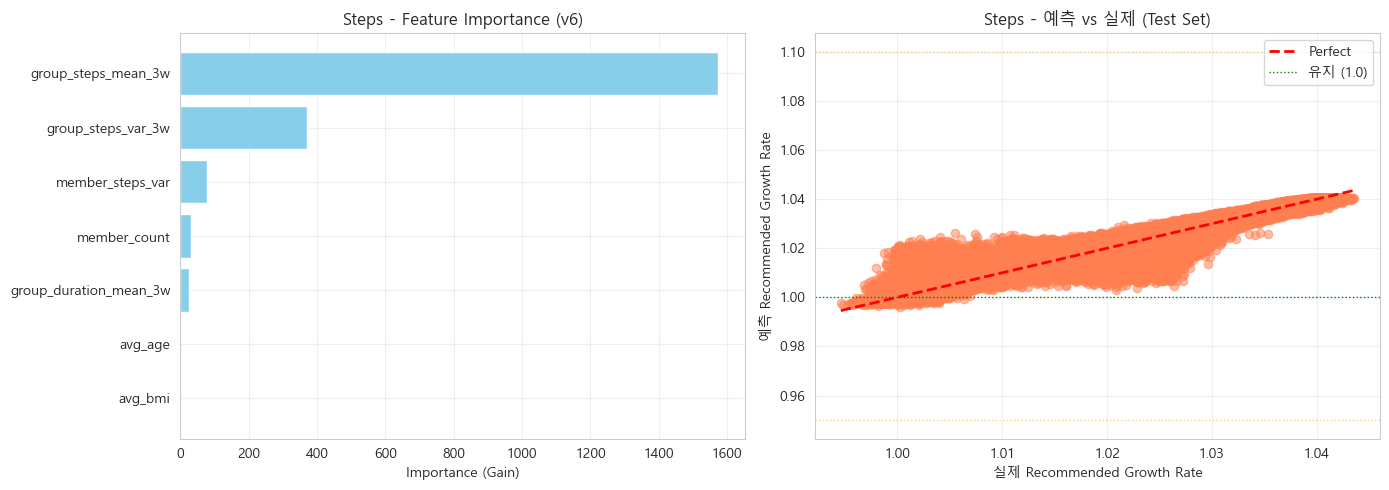

In [5]:
steps_model, steps_metrics = train_and_evaluate(
    metric_name='Steps',
    features=STEPS_FEATURES,
    target_col='recommended_growth_rate',
    data_path='../data/processed/training_steps.csv',
    model_path='../models/goal_steps_model.txt'
)

## 2. Kcal 모델 학습


🚀 Kcal 모델 학습 시작 (v6 Policy-based)
데이터 크기: (10368298, 8)
컬럼 확인: ['member_count', 'avg_age', 'avg_bmi', 'group_kcal_mean_3w', 'group_kcal_var_3w', 'group_duration_mean_3w', 'member_steps_var', 'recommended_growth_rate']

Features (7개):
  - member_count
  - avg_age
  - avg_bmi
  - group_kcal_mean_3w
  - group_kcal_var_3w
  - group_duration_mean_3w
  - member_steps_var

Target: recommended_growth_rate
  - 범위: 0.9894 ~ 1.0417
  - 평균: 1.0203
  - 중앙값: 1.0211

Train: 8294638, Test: 2073660

📊 평가 결과:
  Train RMSE: 0.003121
  Test RMSE:  0.003125
  Train MAE:  0.002383
  Test MAE:   0.002386
  Train R²:   0.5725
  Test R²:    0.5710

🔍 Feature Importance:
               feature  importance
    group_kcal_mean_3w  410.192410
     group_kcal_var_3w  339.027880
group_duration_mean_3w  256.435020
      member_steps_var   65.114739
          member_count   34.601683
               avg_bmi    4.224706
               avg_age    0.100006

✅ 모델 저장 완료: ../models/goal_kcal_model.txt


C:\Users\SSAFY\AppData\Local\Temp\ipykernel_20676\3960347462.py:106: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
c:\Users\SSAFY\Desktop\LinkCare\S13P31A307\AI\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


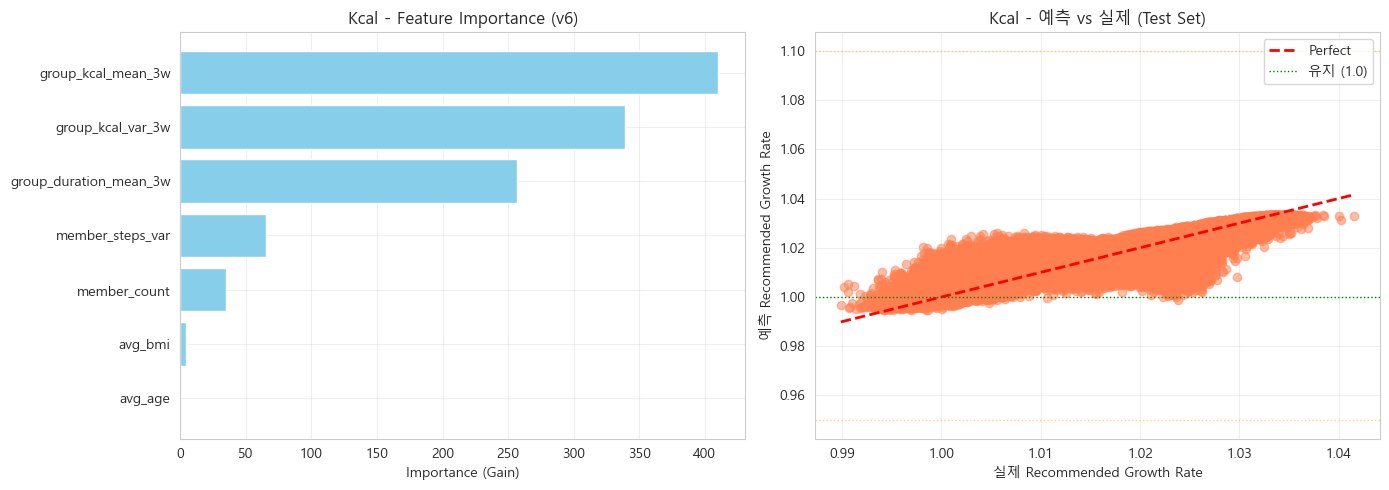

In [6]:
kcal_model, kcal_metrics = train_and_evaluate(
    metric_name='Kcal',
    features=KCAL_FEATURES,
    target_col='recommended_growth_rate',
    data_path='../data/processed/training_kcal.csv',
    model_path='../models/goal_kcal_model.txt'
)

## 3. Duration 모델 학습


🚀 Duration 모델 학습 시작 (v6 Policy-based)
데이터 크기: (10368298, 8)
컬럼 확인: ['member_count', 'avg_age', 'avg_bmi', 'group_duration_mean_3w', 'group_duration_var_3w', 'group_steps_mean_3w', 'member_steps_var', 'recommended_growth_rate']

Features (7개):
  - member_count
  - avg_age
  - avg_bmi
  - group_duration_mean_3w
  - group_duration_var_3w
  - group_steps_mean_3w
  - member_steps_var

Target: recommended_growth_rate
  - 범위: 0.9953 ~ 1.0430
  - 평균: 1.0229
  - 중앙값: 1.0233

Train: 8294638, Test: 2073660

📊 평가 결과:
  Train RMSE: 0.002670
  Test RMSE:  0.002674
  Train MAE:  0.001997
  Test MAE:   0.002000
  Train R²:   0.7382
  Test R²:    0.7373

🔍 Feature Importance:
               feature  importance
group_duration_mean_3w 1255.817751
 group_duration_var_3w  344.257325
      member_steps_var   67.967643
          member_count   37.233865
   group_steps_mean_3w    5.157211
               avg_age    0.176651
               avg_bmi    0.078575

✅ 모델 저장 완료: ../models/goal_duration_model.txt


C:\Users\SSAFY\AppData\Local\Temp\ipykernel_20676\3960347462.py:106: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
c:\Users\SSAFY\Desktop\LinkCare\S13P31A307\AI\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


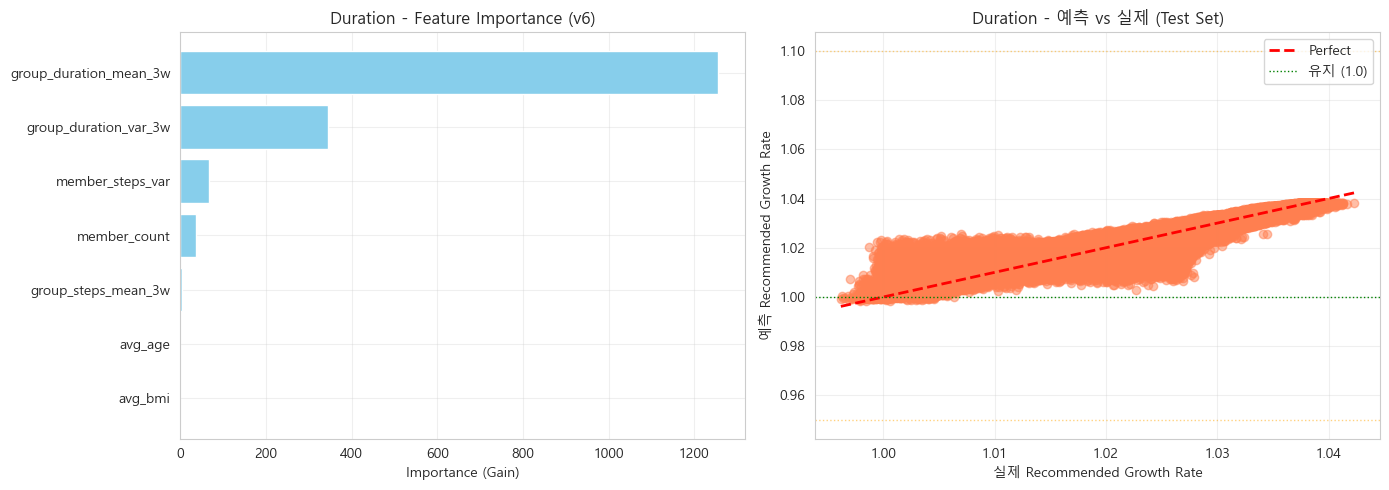

In [7]:
duration_model, duration_metrics = train_and_evaluate(
    metric_name='Duration',
    features=DURATION_FEATURES,
    target_col='recommended_growth_rate',
    data_path='../data/processed/training_duration.csv',
    model_path='../models/goal_duration_model.txt'
)

## 4. Distance 모델 학습


🚀 Distance 모델 학습 시작 (v6 Policy-based)
데이터 크기: (10368298, 8)
컬럼 확인: ['member_count', 'avg_age', 'avg_bmi', 'group_distance_mean_3w', 'group_distance_var_3w', 'group_duration_mean_3w', 'member_steps_var', 'recommended_growth_rate']

Features (7개):
  - member_count
  - avg_age
  - avg_bmi
  - group_distance_mean_3w
  - group_distance_var_3w
  - group_duration_mean_3w
  - member_steps_var

Target: recommended_growth_rate
  - 범위: 0.9941 ~ 1.0451
  - 평균: 1.0231
  - 중앙값: 1.0232

Train: 8294638, Test: 2073660

📊 평가 결과:
  Train RMSE: 0.002521
  Test RMSE:  0.002523
  Train MAE:  0.001873
  Test MAE:   0.001874
  Train R²:   0.7936
  Test R²:    0.7931

🔍 Feature Importance:
               feature  importance
group_distance_mean_3w 1573.570129
 group_distance_var_3w  368.886889
      member_steps_var   77.645503
          member_count   31.575858
group_duration_mean_3w   26.328789
               avg_age    0.142750
               avg_bmi    0.076690

✅ 모델 저장 완료: ../models/goal_distance_model.tx

C:\Users\SSAFY\AppData\Local\Temp\ipykernel_20676\3960347462.py:106: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
c:\Users\SSAFY\Desktop\LinkCare\S13P31A307\AI\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


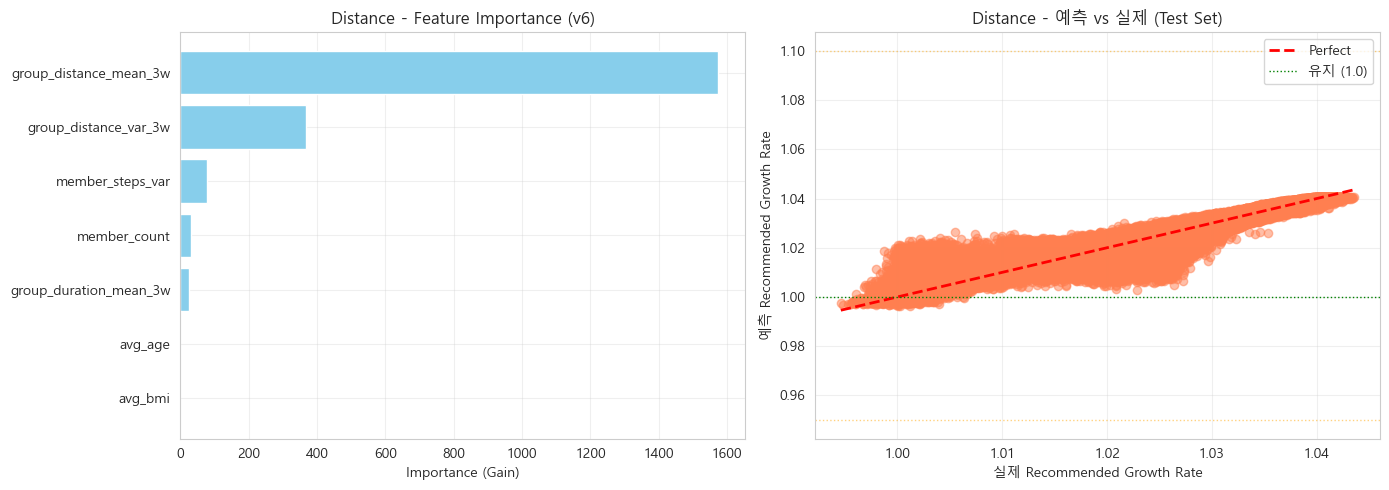

In [8]:
distance_model, distance_metrics = train_and_evaluate(
    metric_name='Distance',
    features=DISTANCE_FEATURES,
    target_col='recommended_growth_rate',
    data_path='../data/processed/training_distance.csv',
    model_path='../models/goal_distance_model.txt'
)

## 5. 전체 결과 요약

In [9]:
# 전체 결과 요약
results_df = pd.DataFrame({
    'Model': ['Steps', 'Kcal', 'Duration', 'Distance'],
    'Test RMSE': [
        steps_metrics['test_rmse'],
        kcal_metrics['test_rmse'],
        duration_metrics['test_rmse'],
        distance_metrics['test_rmse']
    ],
    'Test MAE': [
        steps_metrics['test_mae'],
        kcal_metrics['test_mae'],
        duration_metrics['test_mae'],
        distance_metrics['test_mae']
    ],
    'Test R²': [
        steps_metrics['test_r2'],
        kcal_metrics['test_r2'],
        duration_metrics['test_r2'],
        distance_metrics['test_r2']
    ]
})

print("\n" + "="*60)
print("📈 전체 모델 성능 비교 (v6 Policy-based)")
print("="*60)
print(results_df.to_string(index=False))
print("\n✨ 전체 학습 완료!")
print("\n💡 해석 가이드:")
print("  - RMSE/MAE: 작을수록 좋음 (예측 오차)")
print("  - R²: 1에 가까울수록 좋음 (설명력)")
print("  - Target 범위: 0.95~1.10 (±10% 성장률)")


📈 전체 모델 성능 비교 (v6 Policy-based)
   Model  Test RMSE  Test MAE  Test R²
   Steps   0.002521  0.001873 0.793395
    Kcal   0.003125  0.002386 0.570968
Duration   0.002674  0.002000 0.737300
Distance   0.002523  0.001874 0.793086

✨ 전체 학습 완료!

💡 해석 가이드:
  - RMSE/MAE: 작을수록 좋음 (예측 오차)
  - R²: 1에 가까울수록 좋음 (설명력)
  - Target 범위: 0.95~1.10 (±10% 성장률)


## 6. 모델 테스트 예시 (v6)

In [10]:
# 샘플 입력 데이터 (v6: 7 features)
sample_input = {
    'member_count': 4,
    'avg_age': 35,
    'avg_bmi': 23.5,
    'group_steps_mean_3w': 8000,
    'group_steps_var_3w': 500,
    'group_duration_mean_3w': 45,
    'member_steps_var': 1200
}

# Steps 예측
sample_df = pd.DataFrame([sample_input])
predicted_growth_rate = steps_model.predict(sample_df[STEPS_FEATURES])[0]

# 다음 주 목표 계산
current_avg_steps = sample_input['group_steps_mean_3w']
next_week_goal_total = current_avg_steps * predicted_growth_rate
next_week_goal_per_member = next_week_goal_total / sample_input['member_count']

print("\n" + "="*60)
print("=== 예측 테스트 (v6 Policy-based) ===")
print("="*60)

print(f"\n📥 입력 데이터 (7 features):")
for k, v in sample_input.items():
    print(f"  {k}: {v}")

print(f"\n🎯 예측 결과:")
print(f"  - 권장 성장률: {predicted_growth_rate:.4f}")
print(f"  - 해석: {(predicted_growth_rate - 1) * 100:+.2f}% {'성장' if predicted_growth_rate > 1 else '감소' if predicted_growth_rate < 1 else '유지'}")

print(f"\n📊 목표 계산:")
print(f"  - 현재 3주 평균: {current_avg_steps:,.0f} steps/week")
print(f"  - 다음 주 그룹 목표: {next_week_goal_total:,.0f} steps/week")
print(f"  - 개인당 목표: {next_week_goal_per_member:,.0f} steps/week")

print(f"\n💡 정책 해석:")
if predicted_growth_rate > 1.05:
    print("  → 상승 추세, 안정적 활동 → 도전적 목표 설정")
elif predicted_growth_rate < 0.98:
    print("  → 하락 추세 또는 높은 변동성 → 완화된 목표 설정")
else:
    print("  → 현재 수준 유지 → 안정적 목표 설정")


=== 예측 테스트 (v6 Policy-based) ===

📥 입력 데이터 (7 features):
  member_count: 4
  avg_age: 35
  avg_bmi: 23.5
  group_steps_mean_3w: 8000
  group_steps_var_3w: 500
  group_duration_mean_3w: 45
  member_steps_var: 1200

🎯 예측 결과:
  - 권장 성장률: 1.0173
  - 해석: +1.73% 성장

📊 목표 계산:
  - 현재 3주 평균: 8,000 steps/week
  - 다음 주 그룹 목표: 8,138 steps/week
  - 개인당 목표: 2,035 steps/week

💡 정책 해석:
  → 현재 수준 유지 → 안정적 목표 설정


## 요약

### ✅ v6 Model Training 완료

**학습된 모델**:
1. `goal_steps_model.txt`
2. `goal_kcal_model.txt`
3. `goal_duration_model.txt`
4. `goal_distance_model.txt`

**핵심 특징**:
- 7개 Feature (기존 12개 → 7개)
- Policy-based Target: `recommended_growth_rate` (0.95~1.10)
- 3주 롤링 통계 기반 예측
- 개인 추세 Feature 제거 (규칙 기반 접근)

**다음 단계**:
- FastAPI 서버 구축 (`app/main.py`)
- 실데이터 수집 후 Fine-tuning (v6 → Real-data)
- `success_rate` 추가하여 현실 보정